In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Qiskit Imports
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import n_local
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SPSA
from qiskit_algorithms.utils import algorithm_globals

# Define the Hamiltonian for H2 Molecule
H2_op = SparsePauliOp.from_list(
    [
        ("II", -1.052373245772859),
        ("IZ", 0.39793742484318045),
        ("ZI", -0.39793742484318045),
        ("ZZ", -0.01128010425623538),
        ("XX", 0.18093119978423156),
    ]
)

print(f"Setup Complete. Hamiltonian defined with {H2_op.num_qubits} qubits.")

Setup Complete. Hamiltonian defined with 2 qubits.


In [2]:
# Set a fixed seed for reproducibility across all backends
seed = 170
algorithm_globals.random_seed = seed
np.random.seed(seed)

# VQE Hyperparameters
iterations = 125
ansatz = n_local(H2_op.num_qubits, rotation_blocks="ry", entanglement_blocks="cz")
spsa = SPSA(maxiter=iterations)

print(f"VQE Configuration: SPSA with {iterations} iterations.")

VQE Configuration: SPSA with 125 iterations.


In [4]:
# Initialize the IBM Quantum Service
service = QiskitRuntimeService()

# List of backends to compare
target_backends = ['ibm_fez', 'ibm_marrakesh', 'ibm_torino']

# Dictionary to store convergence data
results_data = {}

# --- FIX: Custom Encoder for NumPy Arrays AND Complex Numbers ---
class AdvancedEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, complex):
            return [obj.real, obj.imag]  # Convert complex to [real, imag] list
        return super().default(obj)
# ---------------------------------------------------------------

print("Starting VQE runs on backend noise models...\n")

for backend_name in target_backends:
    print(f"--- Processing {backend_name} ---")
    
    try:
        # 1. Fetch the real backend to get current calibration data
        real_backend = service.backend(backend_name)
        noise_model = NoiseModel.from_backend(real_backend)
        coupling_map = real_backend.coupling_map
        
        # 2. Save Noise Model and Coupling Map to files
        # We use cls=AdvancedEncoder to handle arrays and complex numbers
        noise_dict = noise_model.to_dict()
        with open(f"{backend_name}_noise_model.json", "w") as f:
            json.dump(noise_dict, f, indent=4, cls=AdvancedEncoder)
            
        # Save Coupling Map
        cmap_list = list(coupling_map) if coupling_map else []
        with open(f"{backend_name}_coupling_map.txt", "w") as f:
            f.write(str(cmap_list))
            
        print(f"   -> Saved noise model & coupling map to disk.")

        # 3. Configure the Simulator with this specific noise profile
        noisy_estimator = AerEstimator(
            options={
                "default_precision": 1e-2,
                "backend_options": {
                    "method": "density_matrix", # Precise simulation method
                    "coupling_map": coupling_map,
                    "noise_model": noise_model,
                },
            }
        )

        # 4. Define a callback to capture energy at every step
        current_values = []
        def store_intermediate_result(eval_count, parameters, mean, std):
            current_values.append(mean)

        # 5. Run VQE
        print(f"   -> Running VQE simulation...")
        vqe = VQE(noisy_estimator, ansatz, optimizer=spsa, callback=store_intermediate_result)
        result = vqe.compute_minimum_eigenvalue(operator=H2_op)
        
        # Store results for this backend
        results_data[backend_name] = current_values
        
        print(f"   -> Final Energy: {result.eigenvalue.real:.5f}")
        print(f"   -> Completed.\n")

    except Exception as e:
        print(f"   [!] Error processing {backend_name}: {e}\n")

print("All runs finished.")

Starting VQE runs on backend noise models...

--- Processing ibm_fez ---
   -> Saved noise model & coupling map to disk.
   -> Running VQE simulation...
   -> Final Energy: -1.73324
   -> Completed.

--- Processing ibm_marrakesh ---
   -> Saved noise model & coupling map to disk.
   -> Running VQE simulation...
   -> Final Energy: -1.85873
   -> Completed.

--- Processing ibm_torino ---
   -> Saved noise model & coupling map to disk.
   -> Running VQE simulation...
   -> Final Energy: -1.83328
   -> Completed.

All runs finished.


In [5]:
# Ensure all result lists are the same length (pad with None if necessary)
max_len = max(len(v) for v in results_data.values())

for name, values in results_data.items():
    if len(values) < max_len:
        values.extend([None] * (max_len - len(values)))

# Create DataFrame
df_comparison = pd.DataFrame(results_data)
df_comparison.index.name = "Iteration"
df_comparison.index += 1  # Start counting iterations at 1

# Save to CSV
csv_filename = "vqe_backend_comparison.csv"
df_comparison.to_csv(csv_filename)

print("Comparison Table (First 5 rows):")
print(df_comparison.head())
print(f"\nFull data saved to: {csv_filename}")

Comparison Table (First 5 rows):
            ibm_fez  ibm_marrakesh  ibm_torino
Iteration                                     
1         -1.460586      -1.612153   -0.676180
2         -1.465127      -1.067065   -0.362981
3         -1.298852      -1.385250   -0.555698
4         -1.572050      -1.205393   -0.367329
5         -1.422497      -1.601705   -0.647571

Full data saved to: vqe_backend_comparison.csv


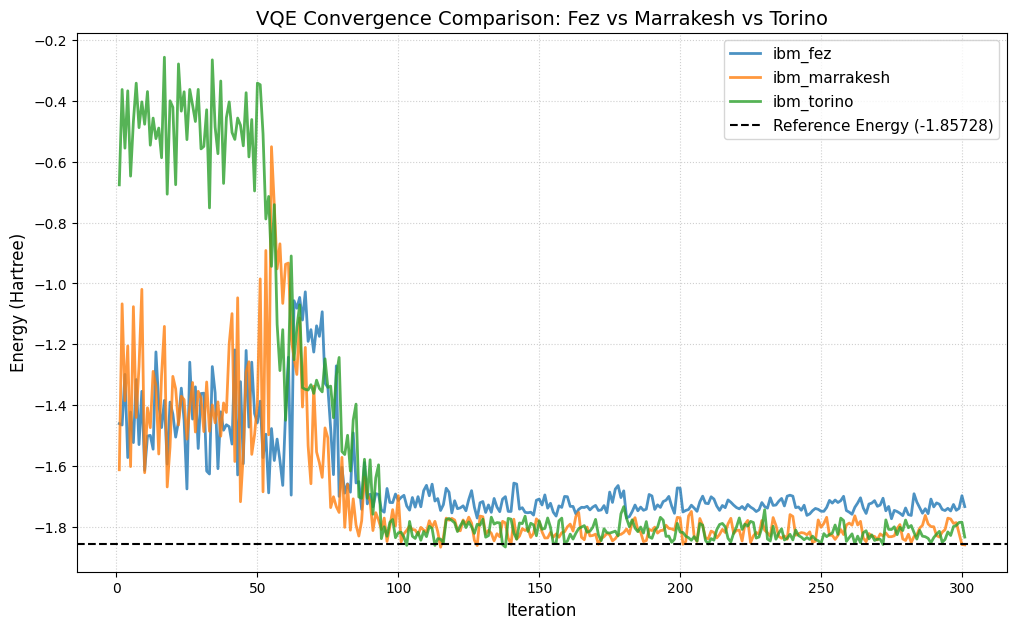

Graph saved as 'vqe_convergence_graph.png'


In [6]:
plt.figure(figsize=(12, 7))

# Plot each backend's data
for name in results_data:
    # Filter out None values for plotting
    clean_data = [x for x in results_data[name] if x is not None]
    clean_index = range(1, len(clean_data) + 1)
    plt.plot(clean_index, clean_data, label=name, linewidth=2, alpha=0.8)

# Add Reference Line (Ground State Energy)
plt.axhline(y=-1.85728, color='black', linestyle='--', label="Reference Energy (-1.85728)")

# Graph Styling
plt.xlabel("Iteration", fontsize=12)
plt.ylabel("Energy (Hartree)", fontsize=12)
plt.title("VQE Convergence Comparison: Fez vs Marrakesh vs Torino", fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# Save and Show
plt.savefig("vqe_convergence_graph.png", dpi=300)
plt.show()

print("Graph saved as 'vqe_convergence_graph.png'")